Accuracy of the Decision Tree Classifier (with entropy criterion): 0.60


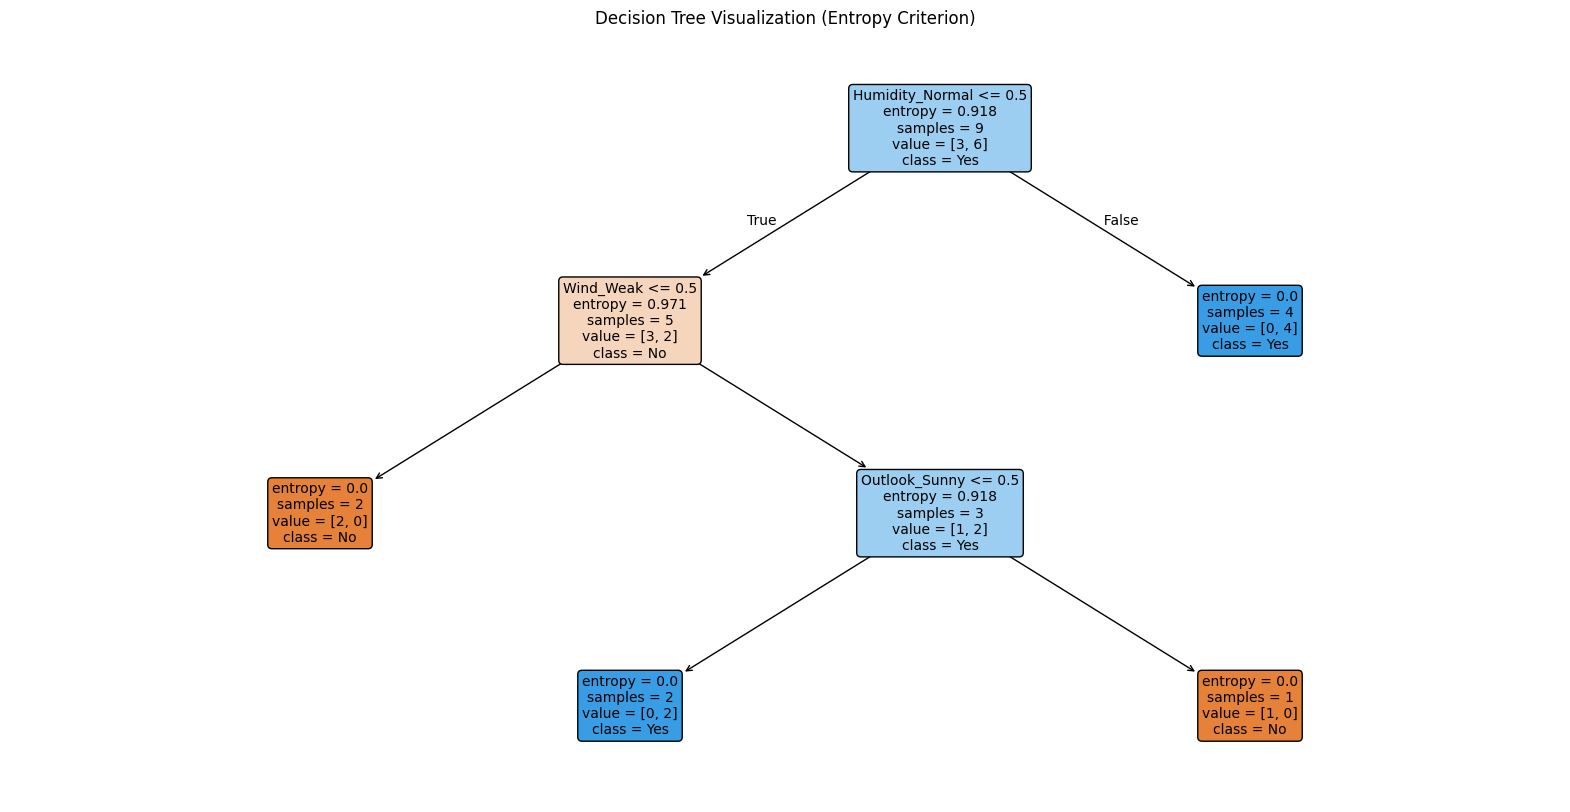

In [4]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rainy', 'Rainy', 'Rainy', 'Overcast', 'Sunny', 'Sunny', 'Rainy', 'Sunny', 'Overcast', 'Overcast', 'Rainy'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild', 'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Strong'],
    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}
df = pd.DataFrame(data)

df_encoded = pd.get_dummies(df[['Outlook', 'Temperature', 'Humidity', 'Wind']], drop_first=True)
y = df['PlayTennis']

X = df_encoded

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

dtree = DecisionTreeClassifier(criterion='entropy', random_state=42)
dtree.fit(X_train, y_train)

y_pred = dtree.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy of the Decision Tree Classifier (with entropy criterion): {accuracy:.2f}')

plt.figure(figsize=(20, 10))
plot_tree(dtree, feature_names=X.columns.tolist(), class_names=dtree.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree Visualization (Entropy Criterion)')
plt.show()

### Calculating Information Gain for the 'Outlook' Feature

Information Gain (IG) is a key metric in decision tree algorithms like ID3. It measures the reduction in entropy (or uncertainty) after splitting a dataset based on an attribute. The attribute with the highest information gain is chosen as the splitting criterion.

Here's how we calculate it for the 'Outlook' feature:

1.  **Calculate the total Entropy of the target variable (`PlayTennis`)**: This measures the impurity of the dataset before any split.

    *   **Entropy(S)** = - P(Yes) * log2(P(Yes)) - P(No) * log2(P(No))

2.  **Calculate the Entropy for each unique value of 'Outlook'**: For each category ('Sunny', 'Overcast', 'Rainy'), we calculate the entropy of `PlayTennis` within that subset.

    *   **Entropy(S_v)** = - P(Yes|v) * log2(P(Yes|v)) - P(No|v) * log2(P(No|v)) (where 'v' is a specific Outlook value)

3.  **Calculate the Weighted Average Entropy after splitting by 'Outlook'**: We sum the entropies of each 'Outlook' category, weighted by the proportion of instances that fall into that category.

    *   **Weighted_Entropy(S, Outlook)** = Sum for each 'v' in 'Outlook' [ (Number of instances with Outlook='v' / Total instances) * Entropy(S_v) ]

4.  **Calculate Information Gain**: Finally, we subtract the weighted average entropy from the total entropy.

    *   **Information_Gain(S, Outlook)** = Entropy(S) - Weighted_Entropy(S, Outlook)

Let's perform these calculations using Python: